# Sonneneruptionen in Röntgenlicht

Das Notebook liest die Flare-Listen der GOES-Satelliten 16 und 18 (NOAA NCEI, 2017 bis 2026, rund 30 000 Flares), fügt Start, Maximum und Ende zu einzelnen Flares zusammen und vergleicht die monatliche Flare-Rate mit der Sonnenfleckenzahl. Es bestimmt den Exponenten der Potenzgesetz-Verteilung der Spitzenflüsse mit Maximum Likelihood, passt die Lichtkurve des stärksten Flares von Zyklus 25 (3. Oktober 2024) an und prüft beide Satelliten gegeneinander und gegen die Echtzeitmeldung X9.0.

Wie oft und wie stark bricht die Sonne aus, wie hängt das mit der Zahl der Sonnenflecken zusammen, und wie genau ist die Klasse eines Flares bestimmt?

#### **Hintergrund**

Ein Flare ist ein plötzlicher Ausbruch auf der Sonne: In wenigen Minuten werden über einer Fleckengruppe bis zu $10^{25}$ J frei, so viel Energie, wie die Menschheit in über zehntausend Jahren verbraucht. Der erste beobachtete Flare, das Carrington-Ereignis von 1859, löste die stärksten bekannten Polarlichter aus und störte Telegrafenleitungen weltweit. Heute ist ein Flare ein Fall für das Weltraumwetter: Das Röntgenlicht eines großen Flares erreicht die Erde nach acht Minuten, ionisiert die obere Atmosphäre auf der Tagseite und unterbricht den Kurzwellenfunk, auf den etwa Flugzeuge über den Ozeanen angewiesen sind. Oft folgt ein koronaler Massenauswurf, der ein bis drei Tage später das Magnetfeld der Erde trifft.

Seit 1975 messen die geostationären GOES-Satelliten der NOAA den Röntgenfluss der ganzen Sonne, und aus ihren Daten kommen die Flare-Klassen (C, M, X), mit denen Warnungen ausgegeben werden. Die Listen aller Flares erlauben auch Fragen der Grundlagenforschung: wie die Flare-Rate dem Sonnenzyklus folgt, warum die Häufigkeit einem Potenzgesetz gehorcht und ob viele kleine Flares die Korona auf Millionen Grad heizen könnten. Dieses Notebook wertet rund 30 000 Flares der Jahre 2017 bis 2026 aus.

Landkarte:

- **Daten**
  - Flare-Listen von GOES-16 und GOES-18 und die monatliche Sonnenfleckenzahl.
- **Reduktion**
  - Aus Ereignissen werden Flares (Schritt 1): 20 651 Flares in einer gemeinsamen Reihe; die Klasse ist der abgeschnittene Spitzenfluss.
- **Eigene Messung**
  - Flare-Rate und Sonnenfleckenzahl (Schritt 2): Die M-Rate wächst wie $R^{1.8}$, die Flares kommen in Schüben.
  - Verteilung der Spitzenflüsse (Schritt 3): Potenzgesetz mit $\alpha = 2.06$ oberhalb von C5.6.
  - Anstieg und Dauer (Schritt 4): Starke Flares dauern etwas länger, der Zusammenhang ist schwach.
- **Modell und Fit**
  - Die Lichtkurve des X8.8-Flares vom 3. Oktober 2024 (Schritt 5): exponentielles Abklingen mit 7.6 Minuten.
- **Eigene Messung gegen den Katalog**
  - GOES-16 gegen GOES-18 und die Echtzeitmeldung (Schritt 6): 0.5 % Unterschied im Fluss, trotzdem oft verschiedene Klassen.

Verwandte Notebooks: der Sonnenfleckenzyklus selbst in [Der Sonnenfleckenzyklus](https://github.com/deltorobarba/science/blob/main/astro/sun_cycle.ipynb), wo auf der Sonne die Flares sitzen in [Wo auf der Sonne Flares entstehen](https://github.com/deltorobarba/science/blob/main/astro/sun_flarepositions.ipynb), der X-Flare vom 3. Oktober 2024 im Bild in [Ein X-Flare im Bild von SDO](https://github.com/deltorobarba/science/blob/main/astro/sun_sdo.ipynb).

#### **Theorie**

##### *1. Flares, GOES und die Flare-Klassen*

Ein **Flare** ist eine plötzliche Freisetzung magnetischer Energie in der Korona über einer **aktiven Region** (einer Fleckengruppe mit starkem Magnetfeld). Verdrillte Magnetfeldlinien ordnen sich neu (**Rekonnexion**), beschleunigen Elektronen und heizen Plasma auf 10 bis 30 Millionen Kelvin. Das heiße Plasma strahlt vor allem im **weichen Röntgenlicht**. Große Flares setzen in wenigen Minuten bis zu $10^{25}$ J frei.

Die GOES-Satelliten messen den Röntgenfluss in zwei Bändern: **XRS-A** (0.05–0.4 nm, härter) und **XRS-B** (0.1–0.8 nm). Die **Flare-Klasse** ist ein Buchstabe für die Zehnerpotenz des Spitzenflusses $F$ in XRS-B und eine Zahl für die Mantisse:

| Klasse | A | B | C | M | X |
|---|---|---|---|---|---|
| $F$ [W/m²] | $10^{-8}$ | $10^{-7}$ | $10^{-6}$ | $10^{-5}$ | $10^{-4}$ |

Ein Flare mit $F = 8.8\cdot 10^{-4}$ W/m² ist also X8.8; oberhalb von X9.9 läuft die Zahl weiter. NOAA schneidet die Mantisse nach einer Nachkommastelle ab, statt zu runden. Die Klasse misst den gesamten Fluss am Maximum, einschließlich des **Hintergrunds** der übrigen Sonne. Ab Klasse M stört die zusätzliche Ionisation der Ionosphäre den Kurzwellenfunk auf der Tagseite.

Bis zum Wechsel auf GOES-16 als Betriebssatellit (2020) hat NOAA die Flüsse von GOES-8 bis GOES-15 mit dem Faktor 0.7 multipliziert, damit sie zu den älteren Satelliten passten. Die wissenschaftlichen Daten verzichten darauf; Klassen aus der Zeit vor 2020 liegen in der Literatur deshalb etwa um den Faktor 0.7 unter den Werten in diesem Notebook.

##### *2. Das Potenzgesetz der Spitzenflüsse*

Kleine Flares sind viel häufiger als große. Ihre Häufigkeit folgt über mehrere Größenordnungen einem **Potenzgesetz** $dN/dF\propto F^{-\alpha}$. Der Exponent entscheidet, ob viele kleine Flares (**Nanoflares**) die Korona heizen könnten: Das geht nur, wenn die Verteilung der Energien steiler als $\alpha = 2$ ist, weil sonst die großen Ereignisse den Energiehaushalt bestimmen (Hudson 1991).

Oberhalb einer Schwelle $F_{\min}$ ist die normierte Dichte $p(F) = \frac{\alpha - 1}{F_{\min}}(F/F_{\min})^{-\alpha}$. Der **Maximum-Likelihood-Schätzer** (MLE), der Wert von $\alpha$, unter dem die beobachteten Werte am wahrscheinlichsten sind, ist für $n$ Flares
$$\hat\alpha = 1 + \frac{n}{\sum_{i}\ln(F_i/F_{\min})},\qquad\sigma_\alpha = \frac{\hat\alpha - 1}{\sqrt n} .$$
Ein Geradenfit an ein logarithmisches Histogramm hängt dagegen von der Wahl der Klassen ab und gewichtet die wenigen großen Flares falsch (Clauset, Shalizi & Newman 2009).

Die **Schwelle** wählt man so, dass die Verteilungsfunktion des Modells, $P(F) = 1 - (F/F_{\min})^{1-\alpha}$, am besten zur empirischen Verteilung $S(F)$ der Werte über der Schwelle passt; man minimiert den **Kolmogorow-Smirnow-Abstand** $D = \max_{F \ge F_{\min}} \vert S(F) - P(F)\vert$, die größte Differenz zwischen den beiden Kurven.

##### *3. Hintergrund und Vollständigkeit*

Ein Flare wird erkannt, wenn sein Fluss deutlich über den Hintergrund der ganzen Sonne steigt. Dieser Hintergrund liegt im Sonnenminimum bei Klasse A bis B, im Maximum oft über C1; ein B5-Flare ist dann unsichtbar. Die Liste ist deshalb nur oberhalb einer gewissen Größe **vollständig**, darunter fehlen Flares, und die Verteilung flacht ab. Zieht man den Hintergrund $F_{bg}$ vom Spitzenfluss ab, misst $\Delta F = F - F_{bg}$ nur den Flare selbst. Der Exponent kann sich dabei ändern, weil der Hintergrund kleine Flares relativ stärker anhebt als große.

##### *4. Flare-Rate und Sonnenfleckenzahl*

Für jeden Monat $i$ sei die Zahl der Flares $N_i$ **Poisson-verteilt** (unabhängige Ereignisse mit fester mittlerer Rate) mit dem Mittelwert $\lambda_i = k\,R_i^{\beta}$, wobei $R_i$ die Sonnenfleckenzahl ist. $k$ und $\beta$ folgen aus der Maximierung der Likelihood (**Poisson-Regression**). Bei einem echten Poisson-Prozess ist die Varianz gleich dem Mittelwert, und $\chi^2/\text{dof} = \sum_i (N_i - \lambda_i)^2/\lambda_i$ geteilt durch die Zahl der Freiheitsgrade liegt nahe 1. Ein Wert $\gg 1$ heißt **Überdispersion**: Die Flares kommen in Schüben, weil wenige komplexe aktive Regionen die meisten großen Flares erzeugen. Der **Spearman-Rangkorrelationskoeffizient** $\rho$ misst, wie gut zwei Größen in derselben Reihenfolge steigen, ohne einen linearen Zusammenhang vorauszusetzen.

##### *5. Die Lichtkurve eines Flares*

Ein Flare steigt in Minuten an und klingt langsamer ab. Nach dem Maximum kühlt das Plasma durch Wärmeleitung und Strahlung; näherungsweise fällt der Fluss exponentiell auf den Hintergrund:
$$F(t) = F_{bg} + A\,e^{-(t - t_p)/\tau}$$
mit der **Abklingzeit** $\tau$. NOAA setzt das Ende eines Flares dort, wo der Fluss auf die Hälfte zwischen Spitze und Hintergrund gefallen ist; im exponentiellen Modell nach $\tau\ln 2$.

Das **Härteverhältnis** XRS-A/XRS-B ist ein Maß für die Temperatur: Heißeres Plasma strahlt relativ mehr im kurzwelligen Band A. Die Ableitung des weichen Röntgenflusses zeigt, wann am meisten Energie zugeführt wird (**Neupert-Effekt**: sie ähnelt dem harten Röntgenfluss der beschleunigten Elektronen).

#### **Daten**

Die Daten stammen von NOAA NCEI (National Centers for Environmental Information) in wissenschaftlicher Qualität (Level 2, Version 2-2-1):
- **Flare-Listen** (`xrsf-l2-flsum`) von GOES-16 (Februar 2017 bis April 2025, dann durch GOES-19 ersetzt) und GOES-18 (seit Juni 2022). Jede Zeile ist ein Ereignis eines Flares: Start, Maximum, Ende (Abfall auf die Hälfte über dem Hintergrund) und Rückkehr zum Hintergrund. Am Start steht der Hintergrundfluss, am Maximum die Klasse. NCEI erzeugt die Datei täglich neu; der Dateiname enthält das Enddatum.
- **1-Minuten-Mittel** (`xrsf-l2-avg1m`) beider Kanäle für einzelne Tage: den 3. Oktober 2024 (stärkster Flare von Zyklus 25 bis Oktober 2026) und Tage, an denen GOES-16 einen Flare nicht in der Liste hat.
- **Monatliche Sonnenfleckenzahl** von SILSO (wie im Notebook zum Sonnenfleckenzyklus).

Die Dateien landen in `astrodata/goes` und `astrodata/silso`; mit `REFRESH = True` lädt das Notebook die neuesten Listen. Die Heliophysics Event Knowledgebase (HEK), die übliche Quelle für Flare-Kataloge in `sunpy`, war beim Schreiben im Oktober 2026 nicht erreichbar. Die NOAA-Listen sind die Grundlage, auf der auch die HEK-Einträge der GOES-Flares beruhen.

**Hintergrund & Fachbegriffe:**
- **Level 2:** nachträglich kalibrierte, wissenschaftlich geprüfte Daten, im Gegensatz zu den Echtzeitdaten für Warnungen.
- **NetCDF:** ein Dateiformat für Messreihen mit Beschreibung der Spalten; `xarray` liest es.
- **Geostationär:** in 36 000 km Höhe über dem Äquator, wo ein Satellit mit der Erde mitläuft; die Sonne ist fast immer sichtbar, außer in kurzen Finsternissen um die Tagundnachtgleichen.

In [1]:
# xarray braucht zum Lesen der GOES-Dateien (NetCDF4) netCDF4 oder h5netcdf; in Colab fehlt das manchmal
import importlib.util, subprocess, sys
if importlib.util.find_spec("netCDF4") is None and importlib.util.find_spec("h5netcdf") is None:
    if "google.colab" not in sys.modules:       # lokal nichts automatisch installieren: pip würde numpy mit aktualisieren
        raise ImportError("Es fehlt netCDF4; bitte lokal selbst installieren, am besten mit conda (conda-forge), "
                          "damit numpy und die übrigen Pakete unverändert bleiben")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "netCDF4"], check=True)

In [2]:
import re, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit, minimize
from scipy.stats import spearmanr

DATA = Path.cwd() / "astrodata" / "goes"
SILSO = Path.cwd() / "astrodata" / "silso"
for d in (DATA, SILSO):
    d.mkdir(parents=True, exist_ok=True)
REFRESH = False                         # True: neueste Flare-Listen und Sonnenfleckenzahl laden
GOES = "https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes"
EVENT_DAY = "2024-10-03"                # Tag des X-Flares für die Lichtkurve

def flsum_path(sat):
    """Neueste Flare-Liste eines Satelliten; der Dateiname enthält Start- und Enddatum."""
    cached = sorted(DATA.glob(f"sci_xrsf-l2-flsum_g{sat}_*.nc"))
    if cached and not REFRESH:
        return cached[-1]
    url = f"{GOES}/goes{sat}/l2/data/xrsf-l2-flsum_science/"
    html = urllib.request.urlopen(url).read().decode()
    name = sorted(set(re.findall(rf"sci_xrsf-l2-flsum_g{sat}_s\d+_e\d+_v[\d-]+\.nc", html)))[-1]
    urllib.request.urlretrieve(url + name, DATA / name)
    return DATA / name

def avg1m(sat, day):
    """1-Minuten-Mittel beider Kanäle für einen Tag (YYYY-MM-DD) als DataFrame."""
    d = day.replace("-", "")
    name = f"sci_xrsf-l2-avg1m_g{sat}_d{d}_v2-2-1.nc"
    if not (DATA / name).exists():
        urllib.request.urlretrieve(f"{GOES}/goes{sat}/l2/data/xrsf-l2-avg1m_science/{d[:4]}/{d[4:6]}/{name}", DATA / name)
    ds = xr.open_dataset(DATA / name)
    return ds[["xrsa_flux", "xrsb_flux", "xrsa_flag", "xrsb_flag"]].to_dataframe()

def read_flares(sat):
    """Aus den Ereigniszeilen einen Flare pro Maximum machen: Start davor, Ende danach."""
    df = xr.open_dataset(flsum_path(sat)).to_dataframe().reset_index()
    df["status"] = df.status.astype(str)
    df = df.sort_values("time", kind="stable")
    st = df[df.status == "EVENT_START"][["time", "background_flux"]].rename(columns={"time": "t_start", "background_flux": "bg"})
    pk = df[df.status == "EVENT_PEAK"][["time", "xrsb_flux", "flare_class"]].rename(
        columns={"time": "t_peak", "xrsb_flux": "F", "flare_class": "klasse"})
    en = df[df.status == "EVENT_END"][["time", "integrated_flux"]].rename(columns={"time": "t_end", "integrated_flux": "fluenz"})
    f = pd.merge_asof(pk, st, left_on="t_peak", right_on="t_start", direction="backward")
    f = pd.merge_asof(f, en, left_on="t_peak", right_on="t_end", direction="forward")
    late = f.t_end > f.t_peak.shift(-1)          # ein Ende nach dem nächsten Maximum gehört nicht mehr dazu
    f.loc[late, ["t_end", "fluenz"]] = [pd.NaT, np.nan]
    f["F"] = f.F.astype(float)
    f["dF"] = f.F - f.bg                         # Spitzenfluss ohne Hintergrund
    f["anstieg"] = (f.t_peak - f.t_start).dt.total_seconds() / 60
    f["abfall"] = (f.t_end - f.t_peak).dt.total_seconds() / 60
    f["sat"] = sat
    return f

fl = {sat: read_flares(sat) for sat in (16, 18)}
for sat, f in fl.items():
    counts = f.klasse.str[0].value_counts()
    print(f"GOES-{sat}: {f.t_peak.min():%Y-%m-%d} bis {f.t_peak.max():%Y-%m-%d}, {len(f)} Flares  "
          + "  ".join(f"{c}: {counts.get(c, 0)}" for c in "ABCMX") + f"   (Datei {flsum_path(sat).name})")

# SILSO-Monatsmittel (dieselbe Datei wie in sun_cycle.ipynb)
p = SILSO / "snmtotcsv.csv"
if REFRESH or not p.exists():
    urllib.request.urlretrieve("https://www.sidc.be/SILSO/INFO/snmtotcsv.php", p)
ssn = pd.read_csv(p, sep=";", names=["jahr", "monat", "t", "sn", "sd", "n_beob", "definitiv"])
ssn.index = pd.PeriodIndex.from_fields(year=ssn.jahr, month=ssn.monat, freq="M")

GOES-16: 2017-02-09 bis 2025-04-06, 16085 Flares  A: 2  B: 4780  C: 9612  M: 1609  X: 82   (Datei sci_xrsf-l2-flsum_g16_s20170209_e20250406_v2-2-1.nc)
GOES-18: 2022-06-17 bis 2026-10-11, 13660 Flares  A: 0  B: 942  C: 10806  M: 1819  X: 93   (Datei sci_xrsf-l2-flsum_g18_s20220617_e20261011_v2-2-1.nc)


* Die **Ausgabe** gibt die beiden Listen: GOES-16 von Februar 2017 bis April 2025 mit 16 085 Flares, GOES-18 von Juni 2022 bis Oktober 2026 mit 13 660. Fast alle sind Klasse B oder C; Klasse A fehlt praktisch, weil solche Flares kaum je über den Hintergrund kommen. GOES-16 hat mehr B-Flares (4780 gegen 942), weil es die ruhigen Jahre 2018 bis 2020 beobachtet hat, in denen der Hintergrund niedrig war.

#### **Reduktion**

##### *1. Aus Ereignissen werden Flares*

Wie viele Flares stehen in den Listen, und lässt sich die Klasse aus dem Spitzenfluss genau nachrechnen? Vorher vorhersagen: Bei welchem Anteil der Flares stimmt eine gerundete Klasse mit der Liste überein?

Die Liste hat für jeden Flare mehrere Zeilen (Start, Maximum, Ende). Zu jedem Maximum wird der letzte Start davor und das erste Ende danach gesucht; ein Ende nach dem nächsten Maximum gehört nicht mehr dazu. Daraus folgen Anstieg, Abfall und der Spitzenfluss ohne Hintergrund. Die Klasse wird aus dem Spitzenfluss einmal abgeschnitten und einmal gerundet berechnet. Für eine gemeinsame Reihe 2017 bis 2026 wird GOES-16 bis zu seinem letzten Tag genommen, danach GOES-18 (Theorie, Abschnitt 1).

**Hintergrund & Fachbegriffe:**
- **Ereignis und Flare:** Ein Flare besteht in der Liste aus mehreren Ereigniszeilen; erst ihre Zuordnung ergibt einen Flare mit Start, Maximum und Ende.
- **Abschneiden und Runden:** 8.86 wird abgeschnitten zu 8.8, gerundet zu 8.9.
- **Hintergrund:** der Röntgenfluss der ganzen Sonne vor dem Flare, aus der Startzeile.

In [3]:
def goes_class(F, rounding=False):
    """Klasse aus dem Spitzenfluss; NOAA schneidet die Mantisse nach einer Nachkommastelle ab."""
    e = np.clip(np.floor(np.log10(F)).astype(int), -8, -4)
    mant = F / 10.0 ** e
    mant = np.round(mant, 1) if rounding else np.floor(mant * 10 + 1e-9) / 10
    return np.array([f"{'ABCMX'[k + 8]}{m:.1f}" for k, m in zip(e, mant)])

for sat, f in fl.items():
    trunc = np.mean(goes_class(f.F.values) == f.klasse.values)
    rnd = np.mean(goes_class(f.F.values, rounding=True) == f.klasse.values)
    print(f"GOES-{sat}: eigene Klasse = Listenklasse bei {trunc:.1%} (abgeschnitten) bzw. {rnd:.1%} (gerundet); "
          f"{f.t_end.isna().mean():.0%} ohne Ende (nächster Flare begann vorher)")

# Eine Reihe für 2017 bis heute: GOES-16 bis zu seinem letzten Tag, danach GOES-18
cut = fl[16].t_peak.max()
allf = pd.concat([fl[16], fl[18][fl[18].t_peak > cut]], ignore_index=True)
print(f"\nGemeinsame Reihe: {len(allf)} Flares von {allf.t_peak.min():%Y-%m} bis {allf.t_peak.max():%Y-%m} "
      f"(GOES-16 bis {cut:%Y-%m-%d}, danach GOES-18)")
print("\nDie zehn stärksten Flares:")
print(allf.nlargest(10, "F")[["t_peak", "klasse", "anstieg", "abfall", "bg", "sat"]].to_string(index=False))

GOES-16: eigene Klasse = Listenklasse bei 100.0% (abgeschnitten) bzw. 50.5% (gerundet); 13% ohne Ende (nächster Flare begann vorher)
GOES-18: eigene Klasse = Listenklasse bei 100.0% (abgeschnitten) bzw. 50.4% (gerundet); 13% ohne Ende (nächster Flare begann vorher)

Gemeinsame Reihe: 20651 Flares von 2017-02 bis 2026-10 (GOES-16 bis 2025-04-06, danach GOES-18)

Die zehn stärksten Flares:
             t_peak klasse  anstieg  abfall           bg  sat
2017-09-06 12:02:00  X14.6     10.0     8.0 8.114693e-06   16
2017-09-10 16:06:00  X12.9     32.0    25.0 6.477831e-07   16
2024-10-03 12:18:00   X8.9     10.0     8.0 9.305923e-06   16
2024-05-14 16:51:00   X8.6      5.0    10.0 5.033336e-06   16
2026-02-01 23:57:00   X8.1     13.0     7.0 1.042265e-05   18
2024-10-01 22:20:00   X7.0     22.0     8.0 6.726740e-06   16
2024-05-11 01:23:00   X5.8     13.0    15.0 1.001130e-05   16
2025-11-11 10:04:00   X5.1     15.0    13.0 2.835215e-06   18
2023-12-31 21:55:00   X4.9     19.0    12.0 1.89226

* Die **erste Ausgabe** zeigt, dass die eigene Klasse bei 100 % der Flares mit der Liste übereinstimmt, wenn man die Mantisse wie NOAA abschneidet, beim Runden nur bei der Hälfte. Bei 13 % der Flares beginnt der nächste Flare, bevor der Fluss auf die halbe Höhe gefallen ist; sie haben kein Ende.
* Die gemeinsame Reihe hat 20 651 Flares von Februar 2017 bis Oktober 2026. An der Spitze der **zehn stärksten** stehen die Flares vom 6. und 10. September 2017 mit X14.6 und X12.9. Damals gemeldet wurden X9.3 und X8.2: Der Faktor 0.7 aus Abschnitt 1 der Theorie erklärt den größten Teil (9.3/0.7 = 13.3), der Rest von etwa 10 % ist ein Unterschied der Kalibrierung.
* Der stärkste Flare von Zyklus 25 ist der vom 3. Oktober 2024 mit X8.9 bei GOES-16; er wird in Schritt 5 genauer untersucht. Die Anstiegszeiten der X-Flares reichen von 5 bis 32 Minuten, und der Hintergrund lag bei vielen schon nahe der M-Klasse.

#### **Eigene Messung**

##### *2. Flare-Rate und Sonnenfleckenzahl*

Wie eng folgt die Zahl der Flares pro Monat der Sonnenfleckenzahl, und gilt das für kleine und große Flares gleichermaßen? Vorher vorhersagen: Wächst die Zahl der M-Flares linear mit der Sonnenfleckenzahl oder schneller?

Für jeden vollständigen Monat werden die Flares ab C1, ab M1 und ab X1 gezählt und mit der Sonnenfleckenzahl von SILSO verglichen: mit der Spearman-Korrelation und für die M-Flares mit einer Poisson-Regression $N = k\,R^\beta$. Dazu kommt eine Tabelle pro Jahr (Theorie, Abschnitt 4).

**Hintergrund & Fachbegriffe:**
- **Spearman-Korrelation $\rho$:** misst, ob zwei Größen gemeinsam steigen, über die Ränge der Werte, also ohne linearen Zusammenhang vorauszusetzen.
- **Poisson-Regression:** passt eine Rate $\lambda = kR^\beta$ so an, dass die beobachteten Zählungen am wahrscheinlichsten sind, wenn jede Monatszahl Poisson-verteilt ist.
- **Überdispersion:** Die Zählungen schwanken stärker als bei einem Poisson-Prozess; $\chi^2/\text{dof}$ gibt den Faktor für die Varianz.

108 Monate von 2017-03 bis 2026-09
≥C1 gegen Sonnenfleckenzahl: Spearman ρ = 0.93
≥M1 gegen Sonnenfleckenzahl: Spearman ρ = 0.90
≥X1 gegen Sonnenfleckenzahl: Spearman ρ = 0.61
M-Flares pro Monat = 0.0075 · R^1.77 (± 0.01 unter Poisson-Annahme)
χ²/dof = 31.6: die Varianz ist 32-mal so groß wie bei Poisson; realistischer Fehler von β ≈ ± 0.04

Flares pro Jahr:
t_peak   2017  2018  2019  2020   2021    2022    2023    2024    2025    2026
C       413.0  33.0  64.0  83.0  443.0  2192.0  2845.0  2794.0  2654.0  1566.0
M        53.0   1.0   3.0   2.0   29.0   193.0   351.0   864.0   332.0   213.0
X         6.0   0.0   0.0   0.0    1.0     7.0    13.0    50.0    18.0    13.0
SN       22.0   7.0   4.0   9.0   29.0    83.0   125.0   155.0   123.0    85.0


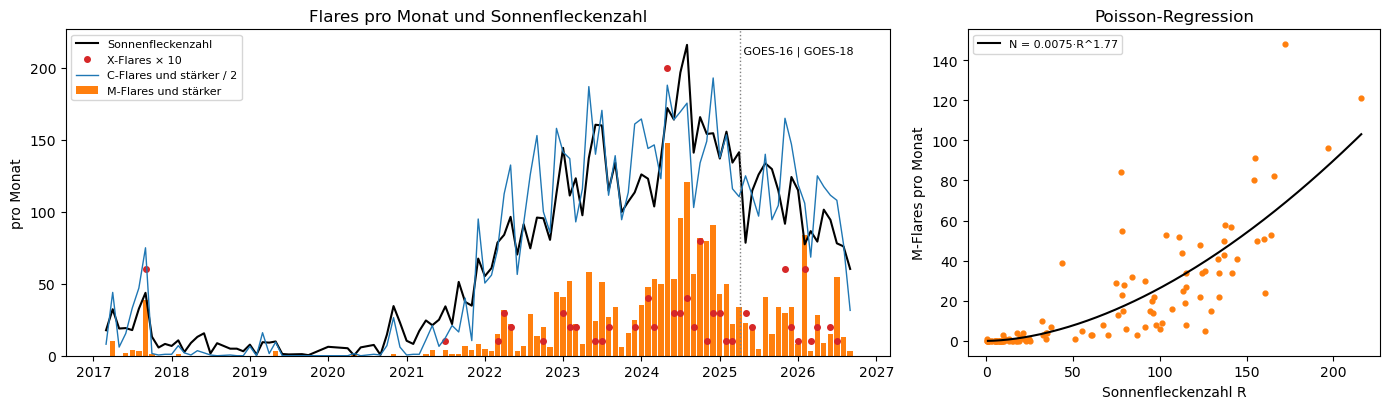

In [4]:
allf["monat"] = allf.t_peak.dt.to_period("M")
rate = allf.groupby("monat").F.agg(C=lambda x: (x >= 1e-6).sum(), M=lambda x: (x >= 1e-5).sum(),
                                   X=lambda x: (x >= 1e-4).sum())
rate = rate.iloc[1:-1].join(ssn.sn, how="inner")      # angebrochene erste und letzte Monate weglassen
print(f"{len(rate)} Monate von {rate.index[0]} bis {rate.index[-1]}")
for c in ("C", "M", "X"):
    rho, p = spearmanr(rate.sn, rate[c])
    print(f"≥{c}1 gegen Sonnenfleckenzahl: Spearman ρ = {rho:.2f}")

# Poisson-Regression N = k·R^β für die M-Flares (alle Monate haben R > 0)
R, N = rate.sn.values, rate.M.values
nll = lambda q: np.sum(np.exp(q[0]) * R ** q[1] - N * (q[0] + q[1] * np.log(R)))
res = minimize(nll, [np.log(0.01), 1.5], method="BFGS")
k_fit, beta = np.exp(res.x[0]), res.x[1]
lam = k_fit * R ** beta
disp = np.sum((N - lam) ** 2 / lam) / (len(N) - 2)
beta_err = np.sqrt(res.hess_inv[1, 1])
print(f"M-Flares pro Monat = {k_fit:.4f} · R^{beta:.2f} (± {beta_err:.2f} unter Poisson-Annahme)")
print(f"χ²/dof = {disp:.1f}: die Varianz ist {disp:.0f}-mal so groß wie bei Poisson; realistischer Fehler von β ≈ ± {beta_err * np.sqrt(disp):.2f}")
print("\nFlares pro Jahr:")
yearly = allf.groupby(allf.t_peak.dt.year).F.agg(
    C=lambda x: ((x >= 1e-6) & (x < 1e-5)).sum(), M=lambda x: ((x >= 1e-5) & (x < 1e-4)).sum(), X=lambda x: (x >= 1e-4).sum())
yearly["SN"] = ssn.groupby("jahr").sn.mean().reindex(yearly.index).round(0)
print(yearly.T.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [2, 1]})
x = rate.index.to_timestamp()
axes[0].plot(x, rate.sn, c="black", lw=1.5, label="Sonnenfleckenzahl")
axes[0].bar(x, rate.M, width=25, color="tab:orange", label="M-Flares und stärker")
axes[0].plot(x[rate.X > 0], rate.X[rate.X > 0] * 10, "o", c="tab:red", ms=4, label="X-Flares × 10")
axes[0].plot(x, rate.C / 2, c="tab:blue", lw=1, label="C-Flares und stärker / 2")
axes[0].axvline(cut, c="0.5", ls=":", lw=1)
axes[0].text(cut, axes[0].get_ylim()[1] * 0.95, " GOES-16 | GOES-18", fontsize=8, va="top")
axes[0].set_ylabel("pro Monat")
axes[0].set_title("Flares pro Monat und Sonnenfleckenzahl")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].scatter(rate.sn, rate.M, s=12, c="tab:orange")
rr = np.linspace(1, rate.sn.max(), 200)
axes[1].plot(rr, k_fit * rr ** beta, c="black", label=f"N = {k_fit:.4f}·R^{beta:.2f}")
axes[1].set_xlabel("Sonnenfleckenzahl R")
axes[1].set_ylabel("M-Flares pro Monat")
axes[1].set_title("Poisson-Regression")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

* Das **linke Bild** zeigt die Sonnenfleckenzahl (schwarz) mit den C-Flares (blau, halbiert), den M-Flares (orange Balken) und den X-Flares (rote Punkte, mal 10) pro Monat. Alle steigen und fallen mit dem Zyklus: fast keine Flares im Minimum 2018 bis 2020, die meisten 2024. Die M-Balken springen aber stark von Monat zu Monat, und X-Flares häufen sich in einzelnen Monaten wie Mai 2024 und Februar 2026.
* Das **rechte Bild** zeigt die M-Flares pro Monat gegen die Sonnenfleckenzahl mit der angepassten Kurve $N = 0.0075\,R^{1.77}$. Die Kurve ist nach oben gekrümmt: Doppelt so viele Flecken heißt mehr als dreimal so viele M-Flares. Die Punkte streuen weit um die Kurve, etwa 84 M-Flares bei $R = 77$ im Februar 2026.
* Die **Ausgabe** gibt die Zahlen: Spearman $\rho = 0.93$ für C-, 0.90 für M- und nur 0.61 für X-Flares, die selten sind und in Schüben kommen. $\chi^2/\text{dof} = 31.6$: Die Monatszahlen schwanken 32-mal so stark wie bei einem Poisson-Prozess, der realistische Fehler von $\beta$ ist deshalb ± 0.04 statt ± 0.01. Pro Jahr: 2019 bei $R = 4$ nur 3 M-Flares, 2024 bei $R = 155$ 864 M- und 50 X-Flares.

##### *3. Die Verteilung der Spitzenflüsse*

Folgen die Spitzenflüsse einem Potenzgesetz, ab welcher Schwelle ist die Liste vollständig, und welchen Exponenten liefert der Maximum-Likelihood-Schätzer? Vorher vorhersagen: Wird der Exponent größer oder kleiner, wenn man den Hintergrund abzieht?

Für 41 Schwellen zwischen $3\cdot10^{-7}$ und $3\cdot10^{-5}$ W/m² werden der MLE-Exponent und der KS-Abstand berechnet, einmal für den Spitzenfluss $F$ und einmal für $\Delta F$ ohne Hintergrund; die Schwelle mit dem kleinsten Abstand gewinnt. Dazu kommt der Hintergrund am Flarestart pro Jahr (Theorie, Abschnitte 2 und 3).

**Hintergrund & Fachbegriffe:**
- **Komplementäre Verteilungsfunktion:** der Anteil der Flares mit größerem Fluss als $F$; für ein Potenzgesetz mit Exponent $\alpha$ ist sie in doppelt logarithmischer Darstellung eine Gerade mit Steigung $1 - \alpha$.
- **KS-Abstand $D$:** die größte Differenz zwischen gemessener und angepasster Verteilungsfunktion; je kleiner, desto besser passt das Potenzgesetz ab dieser Schwelle.
- **Vollständigkeit:** Oberhalb der Schwelle steht praktisch jeder Flare in der Liste, darunter fehlen viele.

Spitzenfluss F         F_min = 6.3e-06 W/m² (C6.3),  α = 2.268 ± 0.020,  n = 3830,  D = 0.012
ohne Hintergrund ΔF    F_min = 5.6e-06 W/m² (C5.6),  α = 2.061 ± 0.021,  n = 2477,  D = 0.017

Hintergrund am Flarestart (Median) und Anteil über C1:
t_peak      2017    2018    2019    2020    2021    2022    2023    2024    2025    2026
median   2.2e-07 9.2e-08 1.3e-07 1.7e-07 1.8e-07 8.8e-07 1.6e-06 2.6e-06 1.5e-06 9.5e-07
ueber_C1    0.13    0.00    0.01    0.01    0.05    0.44    0.81    0.95    0.77    0.47


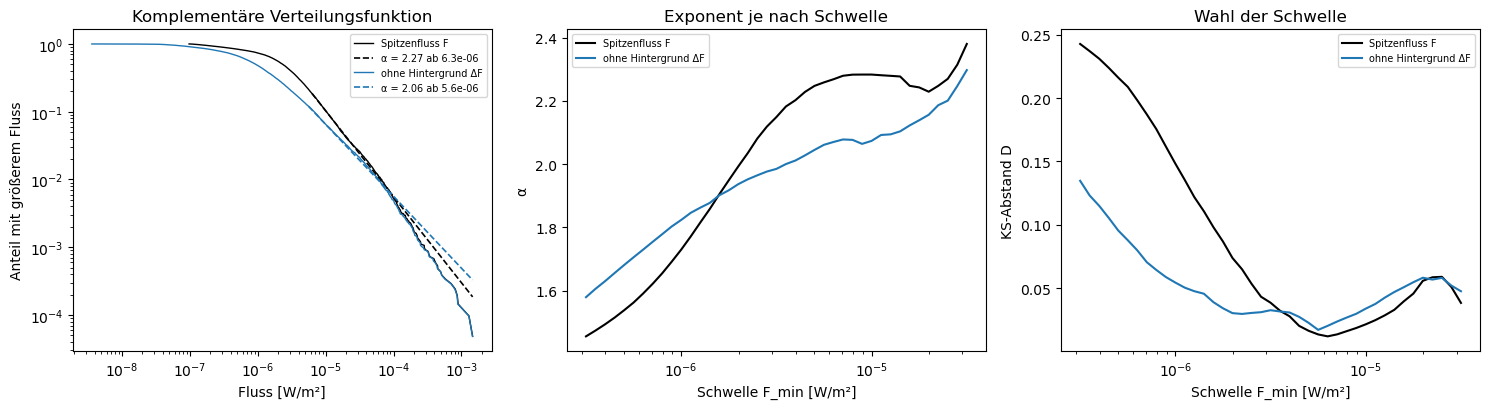

In [5]:
def powerlaw_fit(x, xmins):
    """MLE-Exponent und KS-Abstand für jede Schwelle; Ergebnis mit dem kleinsten Abstand."""
    x = np.sort(x[np.isfinite(x) & (x > 0)])
    rows = []
    for xm in xmins:
        y = x[x >= xm]
        n = len(y)
        a = 1 + n / np.sum(np.log(y / xm))
        D = np.max(np.abs(np.arange(1, n + 1) / n - (1 - (y / xm) ** (1 - a))))
        rows.append((xm, a, (a - 1) / np.sqrt(n), n, D))
    scan = pd.DataFrame(rows, columns=["F_min", "alpha", "fehler", "n", "D"])
    return scan, scan.loc[scan.D.idxmin()]

xmins = np.logspace(-6.5, -4.5, 41)
fits = {}
for label, col in (("Spitzenfluss F", "F"), ("ohne Hintergrund ΔF", "dF")):
    scan, best = powerlaw_fit(allf[col].values, xmins)
    fits[label] = (scan, best, col)
    print(f"{label:<22} F_min = {best.F_min:.1e} W/m² ({goes_class(np.array([best.F_min]))[0]}),  "
          f"α = {best.alpha:.3f} ± {best.fehler:.3f},  n = {best.n:.0f},  D = {best.D:.3f}")

# Hintergrund: Anteil der Flares, deren Hintergrund über C1 lag
bg_year = allf.groupby(allf.t_peak.dt.year).bg.agg(median="median", ueber_C1=lambda b: (b > 1e-6).mean())
print("\nHintergrund am Flarestart (Median) und Anteil über C1:")
print(bg_year.T.to_string(float_format=lambda v: f"{v:.1e}" if v < 1e-3 else f"{v:.2f}"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for (label, (scan, best, col)), c in zip(fits.items(), ("black", "tab:blue")):
    x = np.sort(allf[col].dropna().values)
    x = x[x > 0]
    ccdf = 1 - np.arange(len(x)) / len(x)
    axes[0].loglog(x, ccdf, c=c, lw=1, label=label)
    xx = np.logspace(np.log10(best.F_min), np.log10(x.max()), 50)
    frac = best.n / len(x)
    axes[0].loglog(xx, frac * (xx / best.F_min) ** (1 - best.alpha), c=c, ls="--", lw=1.2,
                   label=f"α = {best.alpha:.2f} ab {best.F_min:.1e}")
    axes[1].semilogx(scan.F_min, scan.alpha, c=c, label=label)
    axes[2].semilogx(scan.F_min, scan.D, c=c, label=label)
axes[0].set_xlabel("Fluss [W/m²]")
axes[0].set_ylabel("Anteil mit größerem Fluss")
axes[0].set_title("Komplementäre Verteilungsfunktion")
axes[0].legend(fontsize=7)
axes[1].set_xlabel("Schwelle F_min [W/m²]")
axes[1].set_ylabel("α")
axes[1].set_title("Exponent je nach Schwelle")
axes[2].set_xlabel("Schwelle F_min [W/m²]")
axes[2].set_ylabel("KS-Abstand D")
axes[2].set_title("Wahl der Schwelle")
for ax in axes[1:]:
    ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

* Das **linke Bild** zeigt die komplementäre Verteilungsfunktion für $F$ (schwarz) und $\Delta F$ (blau) mit den angepassten Potenzgesetzen (gestrichelt). Unterhalb von etwa $10^{-6}$ W/m² ist die Kurve flach, dort fehlen Flares. Darüber fällt sie fast gerade ab, wie es ein Potenzgesetz verlangt. Oberhalb von etwa $10^{-4}$ (X1) liegt sie unter den Geraden: Es gibt weniger sehr große Flares als vorhergesagt, aber nur rund hundert, also mit großer Unsicherheit.
* Das **mittlere Bild** zeigt den Exponenten je nach Schwelle: Bei zu tiefer Schwelle ist er zu klein (um 1.5), weil die unvollständigen kleinen Flares mitzählen; ab etwa $5\cdot10^{-6}$ wird er flach, um 2.27 für $F$ und 2.06 für $\Delta F$. Das **rechte Bild** zeigt den KS-Abstand mit einem klaren Minimum bei etwa $6\cdot10^{-6}$ W/m².
* Die **Ausgabe** gibt die Werte: $\alpha = 2.27\pm0.02$ oberhalb von C6.3 mit Hintergrund, $\alpha = 2.06\pm0.02$ oberhalb von C5.6 ohne. Mit Hintergrund ist das Gesetz steiler, weil der Hintergrund kleine Flares über die Schwelle hebt. Der mittlere Hintergrund stieg von A9 (2018) auf C2.6 (2024), und 95 % der Flares von 2024 begannen über einem Hintergrund von C1; deshalb liegt die Schwelle erst bei C5 bis C6.

##### *4. Anstieg und Dauer*

Dauern starke Flares länger als schwache, und wie verhalten sich Anstieg und Abfall zueinander? Vorher vorhersagen: Steigt ein Flare schneller an, als er abfällt?

Für jede Klasse von B bis X werden Median und Streuung von Anstieg (Start bis Maximum) und Abfall (Maximum bis halbe Höhe) berechnet, und für alle Flares die Spearman-Korrelation mit dem Spitzenfluss.

**Hintergrund & Fachbegriffe:**
- **Boxplot:** Die Box reicht vom 25-%- zum 75-%-Quantil, die Linie darin ist der Median, die Striche zeigen die übrige Spanne ohne Ausreißer.
- **Abfall bis zur halben Höhe:** die Zeit, nach der NOAA einen Flare als beendet zählt; das vollständige Abklingen dauert viel länger.

Median in Minuten (Abfall = Maximum bis Hälfte über dem Hintergrund):
   anstieg  abfall      n
F                        
B      8.0     5.0   5413
C      8.0     6.0  13087
M     11.0     8.0   2041
X     15.0     9.0    108

Spearman: log F gegen Anstieg ρ = 0.21, gegen Abfall ρ = 0.14
Anteil der Flares, die schneller ansteigen als abfallen: 25%


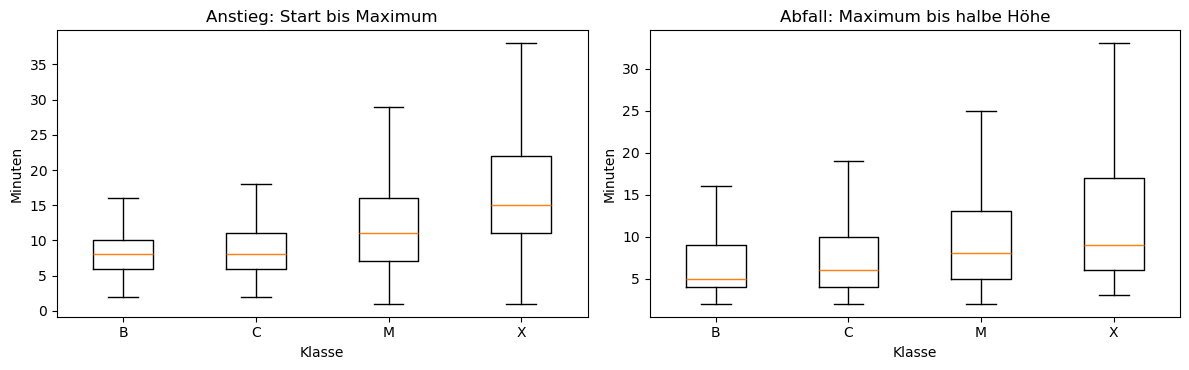

In [6]:
cls = pd.cut(allf.F, [1e-7, 1e-6, 1e-5, 1e-4, 1e-2], labels=["B", "C", "M", "X"], right=False)
summary = allf.groupby(cls, observed=True)[["anstieg", "abfall"]].median()
summary["n"] = allf.groupby(cls, observed=True).size()
print("Median in Minuten (Abfall = Maximum bis Hälfte über dem Hintergrund):")
print(summary.to_string())
ok = allf.abfall.notna()
rho_r, _ = spearmanr(np.log10(allf.F), allf.anstieg)
rho_d, _ = spearmanr(np.log10(allf.F[ok]), allf.abfall[ok])
print(f"\nSpearman: log F gegen Anstieg ρ = {rho_r:.2f}, gegen Abfall ρ = {rho_d:.2f}")
print(f"Anteil der Flares, die schneller ansteigen als abfallen: {(allf.anstieg[ok] < allf.abfall[ok]).mean():.0%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, col, title in zip(axes, ("anstieg", "abfall"), ("Anstieg: Start bis Maximum", "Abfall: Maximum bis halbe Höhe")):
    data = [allf.loc[(cls == c) & allf[col].notna(), col] for c in "BCMX"]
    ax.boxplot(data, showfliers=False)
    ax.set_xticks(range(1, 5), list("BCMX"))
    ax.set_xlabel("Klasse")
    ax.set_ylabel("Minuten")
    ax.set_title(title)
fig.tight_layout()
plt.show()

* Das **Bild** zeigt Boxplots von Anstieg (links) und Abfall bis zur halben Höhe (rechts) für die Klassen B, C, M und X. Der Median des Anstiegs wächst von 8 Minuten (B, C) auf 11 (M) und 15 Minuten (X), der des Abfalls von 5 auf 9 Minuten. Die Boxen überlappen aber stark: Es gibt X-Flares, die in einer Minute ansteigen, und B-Flares, die eine Viertelstunde brauchen.
* Die **Ausgabe** bestätigt den schwachen Zusammenhang: Spearman $\rho = 0.21$ für den Anstieg und 0.14 für den Abfall. Die Dauer hängt mehr von der Geometrie der Magnetfeldschleifen ab als von der Stärke des Flares.
* Nur 25 % der Flares steigen schneller an, als sie auf die halbe Höhe abfallen. Das widerspricht dem Bild vom schnellen Anstieg und langsamen Abklingen nur scheinbar: Der Anstieg zählt hier ab dem Start, wo der Fluss noch kaum über dem Hintergrund liegt, der Abfall nur bis zur halben Höhe.

#### **Modell und Fit**

##### *5. Die Lichtkurve des X-Flares vom 3. Oktober 2024*

Welche Klasse ergibt sich aus den Minutenwerten selbst, wie schnell klingt der Flare ab, und was zeigen die beiden Kanäle über die Temperatur? Vorher vorhersagen: Ist das Plasma am Flussmaximum am heißesten, oder vorher?

Geladen werden die 1-Minuten-Mittel von GOES-18 für 11:30 bis 14:00 UT, nur Minuten mit guter Datenmarke. An die erste Stunde nach dem Maximum wird das exponentielle Abklingen mit relativen Fehlern angepasst; dazu kommen das Härteverhältnis XRS-A/XRS-B und die Ableitung des Flusses (Theorie, Abschnitt 5).

**Hintergrund & Fachbegriffe:**
- **1-Minuten-Mittel:** der Fluss beider Kanäle, über jede Minute gemittelt, mit einer Datenmarke (`flag`) für Erdschatten oder schlechte Messung.
- **Abklingzeit $\tau$:** die Zeit, in der der Flussüberschuss auf $1/e\approx37\,\%$ fällt.
- **Relative Fehler:** Jeder Punkt zählt mit seinem relativen statt absoluten Abstand, sonst bestimmen allein die ersten Minuten mit dem höchsten Fluss den Fit.
- **Härteverhältnis:** XRS-A/XRS-B, steigt mit der Temperatur des Plasmas.

Eigenes Maximum: 12:18 UT, F = 8.806e-04 W/m² → X8.8
Flare-Liste GOES-18: Start 12:08, Maximum 12:18, Ende 12:26, Klasse X8.8, Hintergrund 9.2e-06
Abklingzeit τ = 7.6 ± 0.1 min, Hintergrund danach 1.4e-05 W/m², relative Abweichung 5.0%
Halbe Höhe: nach Modell τ·ln2 = 5.2 min, gemessen 8 min (Liste: Ende nach 8 min)
Härteverhältnis A/B: Maximum 0.42 um 12:16, am Flare-Maximum 0.38
Steilster Anstieg von XRS-B um 12:17, 1 min vor dem Maximum


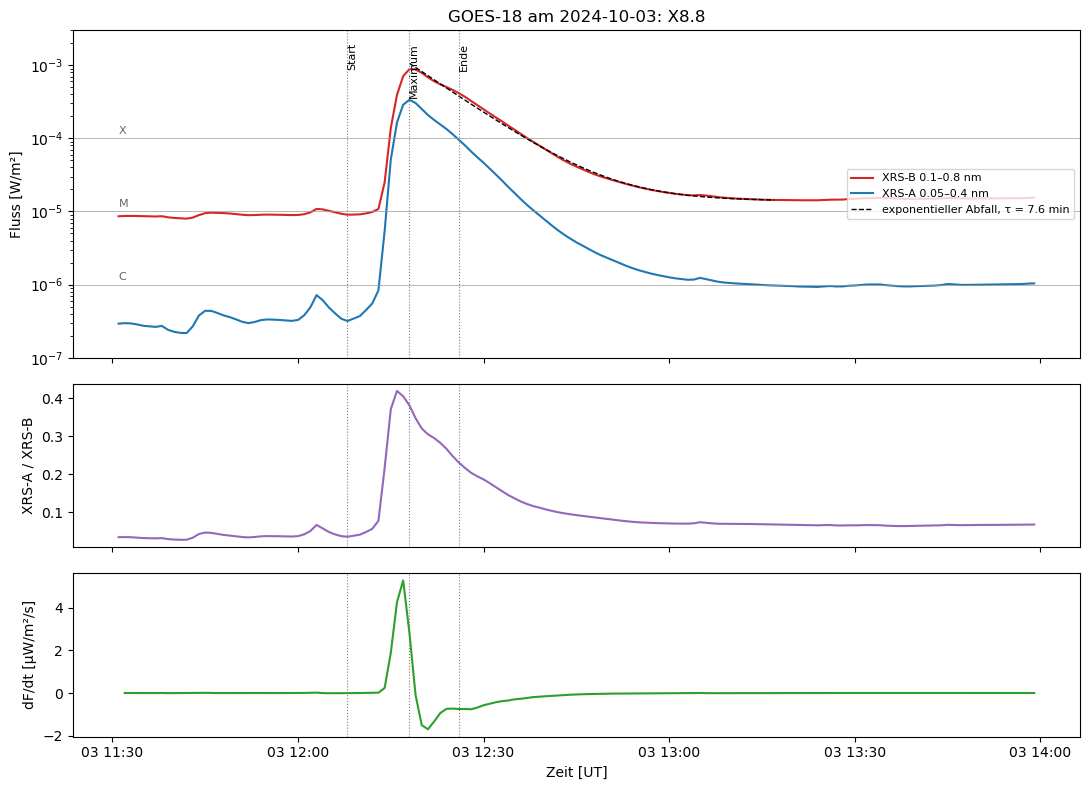

In [7]:
lc = avg1m(18, EVENT_DAY)
lc = lc[(lc.index > f"{EVENT_DAY} 11:30") & (lc.index < f"{EVENT_DAY} 14:00")]
good = (lc.xrsb_flag == 0) & (lc.xrsa_flag == 0)
lc = lc[good]
t_p = lc.xrsb_flux.idxmax()
F_p = lc.xrsb_flux.max()
row = fl[18].loc[(fl[18].t_peak - t_p).abs().idxmin()]
print(f"Eigenes Maximum: {t_p:%H:%M} UT, F = {F_p:.3e} W/m² → {goes_class(np.array([F_p]))[0]}")
print(f"Flare-Liste GOES-18: Start {row.t_start:%H:%M}, Maximum {row.t_peak:%H:%M}, Ende {row.t_end:%H:%M}, "
      f"Klasse {row.klasse}, Hintergrund {row.bg:.1e}")

# Exponentielles Abklingen in der ersten Stunde nach dem Maximum
dec = lc[(lc.index >= t_p) & (lc.index < t_p + pd.Timedelta("60min"))]
xm = (dec.index - t_p).total_seconds() / 60
model = lambda x, A, tau, bgf: bgf + A * np.exp(-x / tau)
# relative Fehler: sonst bestimmen allein die ersten Minuten mit dem höchsten Fluss den Fit
(A, tau, bgf), cov = curve_fit(model, xm, dec.xrsb_flux, p0=[F_p, 10, row.bg], sigma=dec.xrsb_flux)
tau_err = np.sqrt(cov[1, 1])
rel = np.sqrt(np.mean((dec.xrsb_flux / model(xm, A, tau, bgf) - 1) ** 2))
half = lc[(lc.index > t_p) & (lc.xrsb_flux < (F_p + row.bg) / 2)].index[0]
print(f"Abklingzeit τ = {tau:.1f} ± {tau_err:.1f} min, Hintergrund danach {bgf:.1e} W/m², relative Abweichung {rel:.1%}")
print(f"Halbe Höhe: nach Modell τ·ln2 = {tau * np.log(2):.1f} min, gemessen {(half - t_p).total_seconds() / 60:.0f} min "
      f"(Liste: Ende nach {row.abfall:.0f} min)")

ratio = lc.xrsa_flux / lc.xrsb_flux
deriv = lc.xrsb_flux.diff() / 60                 # W/m² pro Sekunde
t_ratio, t_deriv = ratio.idxmax(), deriv.idxmax()
print(f"Härteverhältnis A/B: Maximum {ratio.max():.2f} um {t_ratio:%H:%M}, am Flare-Maximum {ratio[t_p]:.2f}")
print(f"Steilster Anstieg von XRS-B um {t_deriv:%H:%M}, {(t_p - t_deriv).total_seconds() / 60:.0f} min vor dem Maximum")

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
axes[0].semilogy(lc.index, lc.xrsb_flux, c="tab:red", label="XRS-B 0.1–0.8 nm")
axes[0].semilogy(lc.index, lc.xrsa_flux, c="tab:blue", label="XRS-A 0.05–0.4 nm")
axes[0].semilogy(dec.index, model(xm, A, tau, bgf), c="black", ls="--", lw=1, label=f"exponentieller Abfall, τ = {tau:.1f} min")
for lvl, name in zip((1e-6, 1e-5, 1e-4), "CMX"):
    axes[0].axhline(lvl, c="0.6", lw=0.5)
    axes[0].text(lc.index[0], lvl * 1.15, name, fontsize=8, color="0.4")
for tt, name in ((row.t_start, "Start"), (row.t_peak, "Maximum"), (row.t_end, "Ende")):
    for ax in axes:
        ax.axvline(tt, c="0.5", ls=":", lw=0.8)
    axes[0].text(tt, 2e-3, name, fontsize=8, rotation=90, va="top")
axes[0].set_ylim(1e-7, 3e-3)
axes[0].set_ylabel("Fluss [W/m²]")
axes[0].set_title(f"GOES-18 am {EVENT_DAY}: {goes_class(np.array([F_p]))[0]}")
axes[0].legend(fontsize=8, loc="center right")
axes[1].plot(ratio.index, ratio, c="tab:purple")
axes[1].set_ylabel("XRS-A / XRS-B")
axes[2].plot(deriv.index, deriv * 1e6, c="tab:green")
axes[2].set_ylabel("dF/dt [µW/m²/s]")
axes[2].set_xlabel("Zeit [UT]")
fig.tight_layout()
plt.show()

* Das **obere Bild** zeigt den Fluss in beiden Kanälen logarithmisch, mit den Klassengrenzen C, M, X. Vor dem Flare liegt XRS-B (rot) schon bei etwa $9\cdot10^{-6}$, knapp unter M1. Ab 12:13 UT steigt er in fünf Minuten um zwei Größenordnungen auf X8.8 und fällt dann über eine Stunde ab; die schwarz gestrichelte Exponentialkurve folgt dem Abfall genau. XRS-A (blau) steigt stärker und fällt schneller.
* Das **mittlere Bild** zeigt das Härteverhältnis: Es springt beim Anstieg von 0.04 auf 0.42 und erreicht sein Maximum um 12:16, zwei Minuten vor dem Flussmaximum. Das **untere Bild** zeigt die Ableitung des Flusses mit dem steilsten Anstieg um 12:17. Das Plasma ist also zuerst am heißesten und erst danach am dichtesten; die Energie wird vor dem Maximum zugeführt.
* Die **Ausgabe** gibt die Zahlen: eigenes Maximum 12:18 UT mit $8.806\cdot10^{-4}$ W/m², genau wie in der Liste. Die Abklingzeit ist $\tau = 7.6\pm0.1$ Minuten, die Kurve passt in der ersten Stunde auf 5 %, und der Hintergrund danach ($1.4\cdot10^{-5}$) liegt höher als vorher. Die halbe Höhe wird aber erst nach 8 statt nach $\tau\ln2 = 5.2$ Minuten erreicht: Direkt nach dem Maximum wird noch geheizt, der Abfall ist dort langsamer als exponentiell.

#### **Eigene Messung gegen den Katalog**

##### *6. GOES-16 gegen GOES-18 und gegen die Echtzeitmeldung*

Von Juni 2022 bis April 2025 haben beide Satelliten dieselbe Sonne beobachtet. Messen sie denselben Fluss, finden sie dieselben Flares, und woher kommt der Unterschied zur Klasse X9.0, die NOAA am 3. Oktober 2024 in Echtzeit gemeldet hat? Vorher vorhersagen: Wenn sich die Flüsse nur um ein halbes Prozent unterscheiden, wie oft weicht dann die Klasse ab?

Die Flares beider Listen werden über ihre Maxima zugeordnet (höchstens 3 Minuten auseinander) und die Spitzenflüsse verglichen. Für M- und X-Flares, die nur GOES-18 hat, zeigen die Datenmarken der 1-Minuten-Werte von GOES-16, warum sie fehlen. Zum Schluss stehen alle Werte des X-Flares vom 3. Oktober 2024 und der eigene Exponent neben der Literatur.

**Hintergrund & Fachbegriffe:**
- **Erdschatten (Finsternis):** Ein geostationärer Satellit steht um die Tagundnachtgleichen jede Nacht bis zu 72 Minuten im Erdschatten und sieht die Sonne nicht.
- **Echtzeitmeldung:** die Klasse, die das Space Weather Prediction Center (SWPC) der NOAA während des Flares aus vorläufig kalibrierten Daten meldet.
- **Kalibrierung:** die Umrechnung der Rohsignale in physikalische Flüsse; sie wird nachträglich verfeinert.

Überlappung 2022-06-17 bis 2025-04-06: GOES-18 9094 Flares, GOES-16 9716; 8821 gemeinsam (Maximum höchstens 3 min auseinander)
Spitzenfluss GOES-18 / GOES-16: Median 0.9949, mittlere 50 % 0.9916 bis 1.0010
Gleiche Klasse bei 70% der gemeinsamen Flares

M- und X-Flares nur bei GOES-18: 26


                                 n  stärkster                                stunden_UT
grund                                                                                  
Daten gut, Flare nicht erkannt   1   0.000014                                       [1]
Erdschatten (Finsternis)        11   0.000041                                    [4, 5]
schlechte oder fehlende Daten   14   0.000634  [0, 2, 5, 8, 10, 12, 16, 20, 21, 22, 23]
Stärkster: X6.3 am 2024-02-22 22:34 – schlechte oder fehlende Daten

Quelle                                        Fluss [W/m²]  Klasse
eigene Klasse aus den Minutenwerten (GOES-18)     8.806e-04    X8.8
Flare-Liste GOES-18                              8.806e-04    X8.8
Flare-Liste GOES-16                              8.943e-04    X8.9
NOAA SWPC Echtzeit (auch in HEK)                 9.000e-04    X9.0

Exponent der Spitzenflüsse ohne Hintergrund: α = 2.06 ± 0.02; Aschwanden & Freeland (2012), 37 Jahre GOES: α ≈ 1.98


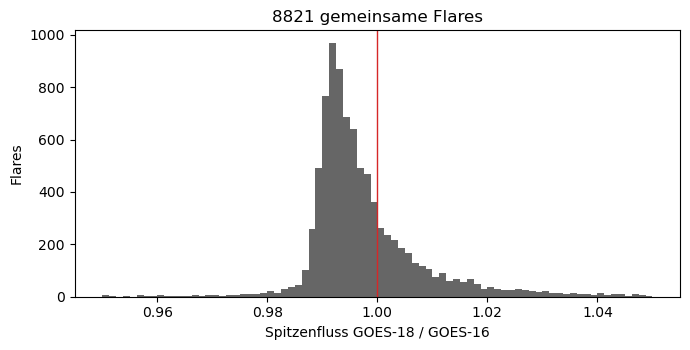

In [8]:
f16, f18 = fl[16], fl[18]
t0, t1 = f18.t_peak.min(), f16.t_peak.max()
a = f18[(f18.t_peak >= t0) & (f18.t_peak <= t1)].sort_values("t_peak")
b = f16[(f16.t_peak >= t0) & (f16.t_peak <= t1)].sort_values("t_peak")
m = pd.merge_asof(a, b[["t_peak", "F", "klasse"]].rename(columns={"t_peak": "t16", "F": "F16", "klasse": "klasse16"}),
                  left_on="t_peak", right_on="t16", direction="nearest", tolerance=pd.Timedelta("3min"))
both = m.dropna(subset=["F16"])
q = both.F / both.F16
print(f"Überlappung {t0:%Y-%m-%d} bis {t1:%Y-%m-%d}: GOES-18 {len(a)} Flares, GOES-16 {len(b)}; "
      f"{len(both)} gemeinsam (Maximum höchstens 3 min auseinander)")
print(f"Spitzenfluss GOES-18 / GOES-16: Median {q.median():.4f}, mittlere 50 % {q.quantile(.25):.4f} bis {q.quantile(.75):.4f}")
print(f"Gleiche Klasse bei {np.mean(both.klasse == both.klasse16):.0%} der gemeinsamen Flares")

only18 = m[m.F16.isna() & (m.F >= 1e-5)]
print(f"\nM- und X-Flares nur bei GOES-18: {len(only18)}")

# Warum fehlen sie bei GOES-16? Die Datenmarken der 1-Minuten-Werte zeigen es (lädt je Tag 0.3 MB).
def reason(tp):
    g16 = avg1m(16, f"{tp:%Y-%m-%d}")
    w = g16.xrsb_flag[(g16.index > tp - pd.Timedelta("20min")) & (g16.index < tp + pd.Timedelta("5min"))]
    w = w.fillna(2).astype(int)                  # fehlende Marke wie schlechte Daten behandeln
    if (w & 1).any():
        return "Erdschatten (Finsternis)"
    if (w & 2).any() or w.empty:
        return "schlechte oder fehlende Daten"
    return "Daten gut, Flare nicht erkannt"
only18 = only18.assign(grund=[reason(tp) for tp in only18.t_peak], stunde=only18.t_peak.dt.hour)
print(only18.groupby("grund").agg(n=("klasse", "size"), stärkster=("F", "max"),
                                  stunden_UT=("stunde", lambda h: sorted(set(h)))).to_string())
big = only18.loc[only18.F.idxmax()]
print(f"Stärkster: {big.klasse} am {big.t_peak:%Y-%m-%d %H:%M} – {big.grund}")

# Der X-Flare vom EVENT_DAY in beiden Listen und in der Echtzeitmeldung
ev = both.loc[both.F.idxmax()]
print(f"\n{'Quelle':<44}{'Fluss [W/m²]':>14}{'Klasse':>8}")
print(f"{'eigene Klasse aus den Minutenwerten (GOES-18)':<44}{F_p:>14.3e}{goes_class(np.array([F_p]))[0]:>8}")
print(f"{'Flare-Liste GOES-18':<44}{ev.F:>14.3e}{ev.klasse:>8}")
print(f"{'Flare-Liste GOES-16':<44}{ev.F16:>14.3e}{ev.klasse16:>8}")
print(f"{'NOAA SWPC Echtzeit (auch in HEK)':<44}{9.0e-4:>14.3e}{'X9.0':>8}")
best = fits["ohne Hintergrund ΔF"][1]
print(f"\nExponent der Spitzenflüsse ohne Hintergrund: α = {best.alpha:.2f} ± {best.fehler:.2f}; "
      f"Aschwanden & Freeland (2012), 37 Jahre GOES: α ≈ 1.98")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(q, bins=np.linspace(0.95, 1.05, 81), color="0.4")
ax.axvline(1, c="tab:red", lw=1)
ax.set_xlabel("Spitzenfluss GOES-18 / GOES-16")
ax.set_ylabel("Flares")
ax.set_title(f"{len(both)} gemeinsame Flares")
fig.tight_layout()
plt.show()

* Die **Ausgabe** zeigt 8821 Flares in beiden Listen. GOES-18 misst im Median 0.5 % weniger als GOES-16, und die mittleren 50 % liegen innerhalb von 1 %. Trotzdem stimmt die Klasse nur bei 70 % überein, weil das Abschneiden der Mantisse schon bei kleinen Unterschieden eine andere Zahl ergibt, etwa 4.99 und 5.01.
* 26 M- und X-Flares hat nur GOES-18: 11 fielen in den Erdschatten von GOES-16 (Finsternisse um 4–5 UT), 14 in Zeiten mit schlechten oder fehlenden Daten, darunter der X6.3-Flare vom 22. Februar 2024, und nur einer (M1.4) wurde trotz guter Daten nicht erkannt.
* Für den Flare vom 3. Oktober 2024 ergeben sich X8.8 (GOES-18, eigene Rechnung und Liste), X8.9 (GOES-16) und X9.0 (Echtzeit). Die Werte unterscheiden sich um 0.6 % bis 2.2 %; das Abschneiden macht daraus drei verschiedene Klassen. Der eigene Exponent ohne Hintergrund, $2.06\pm0.02$, liegt nahe an 1.98 aus 37 Jahren GOES (Aschwanden & Freeland 2012).
* Das **Bild** zeigt das Verhältnis der Spitzenflüsse für alle gemeinsamen Flares: ein schmaler Gipfel knapp unter 1 (rote Linie), mit einem längeren Ausläufer nach oben als nach unten.

#### **Ergebnis**

Beim Lauf vom 2026-10-12 (GOES-16 bis April 2025, GOES-18 bis 11. Oktober 2026):

- **Listen:** GOES-16 enthält 16 085 Flares, GOES-18 13 660; die gemeinsame Reihe 2017–2026 hat 20 651. Die eigene Klasse aus dem Spitzenfluss stimmt bei 100 % der Flares mit der Liste überein, wenn man die Mantisse wie NOAA abschneidet, beim Runden nur bei 50 %. Bei 13 % der Flares beginnt der nächste, bevor der Fluss auf die halbe Höhe gefallen ist; sie haben kein Ende.
- **Stärkste Flares:** An der Spitze stehen die Flares vom 6. und 10. September 2017 mit X14.6 und X12.9. Damals gemeldet wurden X9.3 und X8.2: Der Faktor 0.7 aus Abschnitt 1 der Theorie erklärt den größten Teil (9.3/0.7 = 13.3), der Rest von etwa 10 % ist ein Unterschied der Kalibrierung zwischen den Satelliten. Der stärkste Flare von Zyklus 25 bis Oktober 2026 ist der vom 3. Oktober 2024 (X8.9 bei GOES-16, X8.8 bei GOES-18).
- **Rate und Sonnenfleckenzahl:** Die Zahl der C- und M-Flares pro Monat folgt der Sonnenfleckenzahl eng (Spearman ρ = 0.93 und 0.90), die der X-Flares lockerer (ρ = 0.61). Die M-Rate wächst stärker als linear, $N_M = 0.0075\,R^{1.77 \pm 0.04}$. Die Monatszahlen streuen 32-mal so stark wie bei einem Poisson-Prozess: Im Februar 2026 gab es bei $R = 77$ 84 Flares der Klasse M und stärker, darunter 6 X-Flares, im Monat davor bei $R = 115$ nur 8: Die großen Flares kommen in Schüben aus wenigen komplexen aktiven Regionen. Im Jahr 2019 (mittleres $R = 4$) gab es 3 M-Flares, 2024 ($R = 155$) 864 M- und 50 X-Flares.
- **Potenzgesetz:** Ohne Hintergrund ist $\alpha = 2.06 \pm 0.02$ oberhalb von C5.6 (2477 Flares), nahe an 1.98 aus 37 Jahren GOES-Daten (Aschwanden & Freeland 2012). Mit Hintergrund ergibt sich der steilere Wert $2.27 \pm 0.02$, weil der Hintergrund kleine Flares über die Schwelle hebt. Unterhalb der Schwelle flacht die Verteilung ab: Der mittlere Hintergrund stieg von A9 (2018) auf C2.6 (2024), und 95 % der Flares von 2024 begannen über einem Hintergrund von C1. Oberhalb von etwa X1 gibt es weniger Flares, als das Potenzgesetz vorhersagt; das beruht aber auf nur rund 100 Flares.
- **Dauer:** Der Median des Anstiegs wächst von 8 Minuten (B, C) auf 11 (M) und 15 Minuten (X), der Abfall bis zur halben Höhe von 5 auf 9 Minuten. Der Zusammenhang mit dem Spitzenfluss ist schwach (ρ = 0.21 und 0.14): Die Dauer hängt mehr von der Geometrie der Magnetfeldschleifen ab als von der Stärke.
- **X8.8-Lichtkurve:** Das eigene Maximum (12:18 UT, $8.806\cdot 10^{-4}$ W/m²) gleicht der Liste. Ein Exponential mit $\tau = 7.6 \pm 0.1$ Minuten beschreibt die erste Stunde auf 5 % genau und landet auf einem Hintergrund von $1.4\cdot 10^{-5}$ W/m², höher als vor dem Flare ($9.2\cdot 10^{-6}$). Die halbe Höhe wird erst nach 8 statt nach $\tau\ln 2 = 5.2$ Minuten erreicht: Direkt nach dem Maximum wird noch geheizt, der Abfall ist dort langsamer als exponentiell. Das Härteverhältnis A/B erreicht sein Maximum (0.42) zwei Minuten vor dem Flussmaximum: Das Plasma ist zuerst am heißesten und erst danach am dichtesten.
- **GOES-16 gegen GOES-18:** 8821 Flares stehen in beiden Listen. GOES-18 misst im Median 0.5 % weniger; trotzdem stimmt die Klasse nur bei 70 % überein, weil das Abschneiden der Mantisse schon bei kleinen Unterschieden eine andere Zahl ergibt. 26 M- und X-Flares hat nur GOES-18: 11 fielen in den Erdschatten von GOES-16 (Finsternisse um 4–5 UT im Frühjahr und Herbst), 14 in Zeiten mit schlechten oder fehlenden Daten, darunter der X6.3-Flare vom 22. Februar 2024, und nur einer (M1.4) wurde trotz guter Daten nicht erkannt.
- **Echtzeitmeldung:** Für den Flare vom 3. Oktober 2024 ergeben sich X8.8 (GOES-18), X8.9 (GOES-16) und X9.0 (Echtzeit). Die Werte unterscheiden sich um 0.6 % bis 2.2 %; das Abschneiden macht daraus drei verschiedene Klassen. Die Echtzeitmeldung beruht auf vorläufig kalibrierten Daten, die Listen auf den nachträglich bearbeiteten.

#### **Variationen**

Jeweils zuerst die Vorhersage notieren, dann den Code ändern und prüfen:

1. **Geradenfit statt Likelihood:** Bestimme in Schritt 3 den Exponenten aus einer Geraden durch ein logarithmisches Histogramm mit 20 und mit 50 Bins oberhalb derselben Schwelle. *(Vorhersage: Das Ergebnis hängt von der Binzahl ab und weicht um mehr als den MLE-Fehler ab.)*
2. **Nur das Minimum:** Rechne Schritt 3 nur mit den Flares von 2018 bis 2020. Wie tief liegt die Schwelle jetzt? *(Vorhersage: deutlich tiefer, bei Klasse B, weil der Hintergrund niedrig ist.)*
3. **Sonnenfleckenzahl gegen C-Flares:** Wiederhole die Poisson-Regression für die C-Flares. *(Vorhersage: kleinere Überdispersion, aber ein flacheres β, weil im Maximum der Hintergrund kleine C-Flares verdeckt.)*
4. **Ein anderer Flare:** Setze `EVENT_DAY = "2024-05-14"` (X8.6 bei GOES-16) oder einen Tag aus der Liste der zehn stärksten Flares und vergleiche Abklingzeit und Härteverhältnis.
5. **Fluenz statt Spitzenfluss:** Die Spalte `fluenz` enthält den integrierten Fluss bis zum Ende in J/m². Welcher Exponent ergibt sich dafür?
6. **Die umgekehrte Richtung:** Suche in Schritt 6 die M-Flares, die nur GOES-16 gesehen hat, und prüfe die Datenmarken von GOES-18. *(Vorhersage: Die Finsternisse von GOES-18 liegen um 8–9 UT, weil der Satellit bei 137° West steht und Mitternacht dort später ist.)*

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was passiert bei einem Flare, und warum misst man ihn im Röntgenlicht?</summary>

Verdrillte Magnetfeldlinien über einer aktiven Region ordnen sich neu (Rekonnexion), beschleunigen Elektronen und heizen Plasma auf 10 bis 30 Millionen Kelvin. Plasma dieser Temperatur strahlt vor allem im weichen Röntgenlicht.
</details>

<details><summary>2. Wie ist die Flare-Klasse definiert, und warum ist der X-Flare vom 3. Oktober 2024 X8.8 und nicht X8.9?</summary>

Ein Buchstabe für die Zehnerpotenz des Spitzenflusses in XRS-B (C $10^{-6}$, M $10^{-5}$, X $10^{-4}$ W/m²) und die Mantisse mit einer Nachkommastelle. NOAA schneidet ab statt zu runden: $8.806\cdot10^{-4}$ wird X8.8.
</details>

<details><summary>3. Warum stehen die Flares vom September 2017 heute als X14.6 und X12.9 in der Liste, gemeldet wurden aber X9.3 und X8.2?</summary>

Bis 2020 hat NOAA die Flüsse mit dem Faktor 0.7 multipliziert, damit sie zu älteren Satelliten passten; die wissenschaftlichen Daten verzichten darauf. Der Rest von etwa 10 % ist ein Unterschied der Kalibrierung.
</details>

<details><summary>4. Wie hängt die Zahl der M-Flares von der Sonnenfleckenzahl ab?</summary>

Stärker als linear, $N_M = 0.0075\,R^{1.77\pm0.04}$ pro Monat. Die Monatszahlen schwanken 32-mal so stark wie bei einem Poisson-Prozess, weil wenige komplexe aktive Regionen die meisten großen Flares erzeugen.
</details>

<details><summary>5. Warum schätzt man den Exponenten eines Potenzgesetzes mit Maximum Likelihood und nicht mit einer Geraden im Histogramm?</summary>

Der Geradenfit hängt von der Wahl der Klassen ab und gewichtet die wenigen großen Werte falsch. Der MLE-Schätzer $\hat\alpha = 1 + n/\sum\ln(F_i/F_{\min})$ braucht keine Klassen und hat den Fehler $(\hat\alpha - 1)/\sqrt n$.
</details>

<details><summary>6. Wie wählt man die Schwelle, ab der das Potenzgesetz gilt, und warum liegt sie so hoch?</summary>

Man nimmt die Schwelle mit dem kleinsten Kolmogorow-Smirnow-Abstand zwischen Daten und Modell. Sie liegt bei C5 bis C6, weil der Hintergrund im Maximum über C1 liegt und kleinere Flares darin untergehen.
</details>

<details><summary>7. Warum ändert sich der Exponent, wenn man den Hintergrund abzieht, und warum ist das für die Heizung der Korona wichtig?</summary>

Der Hintergrund hebt kleine Flares relativ stärker an als große; ohne ihn ist $\alpha = 2.06$ statt 2.27. Nanoflares können die Korona nur heizen, wenn die Energieverteilung steiler als $\alpha = 2$ ist; der gemessene Wert liegt nahe an dieser Grenze.
</details>

<details><summary>8. Dauern starke Flares länger?</summary>

Etwas: Der Median des Anstiegs wächst von 8 Minuten (B, C) auf 15 Minuten (X), der Zusammenhang ist aber schwach ($\rho = 0.21$). Die Dauer hängt mehr von der Geometrie der Magnetfeldschleifen ab.
</details>

<details><summary>9. Was zeigen Härteverhältnis und Ableitung der Lichtkurve des X8.8-Flares?</summary>

Das Härteverhältnis XRS-A/XRS-B ist am größten zwei Minuten vor dem Flussmaximum, die Ableitung eine Minute davor: Das Plasma ist zuerst am heißesten, dann am dichtesten, und die Energie wird vor dem Maximum zugeführt.
</details>

<details><summary>10. Warum stimmen die Klassen von GOES-16 und GOES-18 nur bei 70 % der Flares überein?</summary>

Die Flüsse unterscheiden sich im Median nur um 0.5 %, aber das Abschneiden der Mantisse macht schon aus kleinen Unterschieden verschiedene Klassen, etwa M4.9 und M5.0.
</details>

<details><summary>11. Warum fehlen in einer Liste manchmal große Flares?</summary>

Weil der Satellit im Erdschatten stand (Finsternisse um die Tagundnachtgleichen) oder die Daten schlecht waren. Von 26 M- und X-Flares, die nur GOES-18 hat, fehlten bei GOES-16 nur einer trotz guter Daten.
</details>

#### **Nächste Schritte**

So würde eine Analyse in der Forschung weitergehen:
- **Temperatur und Emissionsmaß:** Aus dem Verhältnis der beiden Kanäle folgen mit den Antwortfunktionen der Detektoren die Temperatur und die Menge des heißen Plasmas (White, Thomas & Schwartz 2005; in Python mit `sunkit-instruments`).
- **Neupert-Effekt:** Die Ableitung des weichen Röntgenflusses ähnelt dem harten Röntgenfluss der beschleunigten Elektronen. Vergleich mit Daten von STIX auf Solar Orbiter oder Fermi GBM.
- **Flare-Vorhersage:** Merkmale des Magnetfelds der aktiven Regionen (SHARP-Parameter aus SDO/HMI) als Eingabe für Klassifikatoren, die vorhersagen, ob eine Region in den nächsten 24 Stunden einen M-Flare erzeugt.
- **Wo der Flare stattfand:** Bilder von SDO im extremen UV und Magnetogramme der aktiven Region zeigt das Notebook [Ein X-Flare im Bild von SDO](https://github.com/deltorobarba/science/blob/main/astro/sun_sdo.ipynb).

#### **Referenzen**

- NOAA NCEI: *GOES-R XRS Level 2 Science Data* (Flare-Listen und 1-Minuten-Mittel), https://www.ncei.noaa.gov/products/goes-r-extreme-ultraviolet-xray-irradiance
- Machol, J. et al. (2022): *GOES-R Series Solar X-ray and Ultraviolet Irradiance*, in *The GOES-R Series*, Elsevier, 233.
- Clauset, A., Shalizi, C. R. & Newman, M. E. J. (2009): *Power-law distributions in empirical data*, SIAM Review 51, 661.
- Aschwanden, M. J. & Freeland, S. L. (2012): *Automated Solar Flare Statistics in Soft X-Rays over 37 Years of GOES Observations*, ApJ 754, 112.
- Hudson, H. S. (1991): *Solar flares, microflares, nanoflares, and coronal heating*, Solar Physics 133, 357.
- Neupert, W. M. (1968): *Comparison of Solar X-Ray Line Emission with Microwave Emission during Flares*, ApJ 153, L59.
- White, S. M., Thomas, R. J. & Schwartz, R. A. (2005): *Updated Expressions for Determining Temperatures and Emission Measures from GOES Soft X-Ray Measurements*, Solar Physics 227, 231.
- SILSO World Data Center: *Sunspot Number*, Royal Observatory of Belgium, https://www.sidc.be/SILSO/